# Linear Regression with L1 regularisation loss penalty

In [90]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

Initialising Linear Model

In [91]:
def linear_model(m, b):

    def predict(x):
        return m*x + b
    return predict

Initialising Linear Data

array([1. , 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2. , 2.1, 2.2,
       2.3, 2.4, 2.5, 2.6, 2.7, 2.8, 2.9, 3. , 3.1, 3.2, 3.3, 3.4, 3.5,
       3.6, 3.7, 3.8, 3.9, 4. , 4.1, 4.2, 4.3, 4.4, 4.5, 4.6, 4.7, 4.8,
       4.9, 5. ])

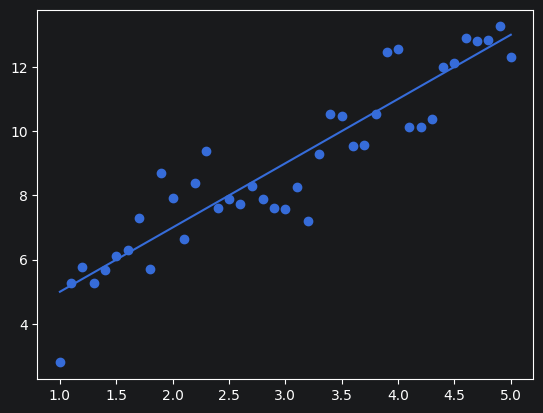

In [92]:
X = np.linspace(1,5,41)
Gauss_noise = np.random.normal(0.0, 1, X.shape)
Y = linear_model(2,3)(X) + Gauss_noise
n = len(X)
plt.plot(X,linear_model(2,3)(X))
plt.scatter(X,Y)
X

Initialising Loss function

In [93]:
def loss(m, b, alpha):
    return (1/n) * sum( val**2 for val in (Y-linear_model(m,b)(X)) ) + alpha * np.abs(m)
def Loss(M, B, alpha):
    residuals = Y - (M[..., None] * X + B[..., None])
    return np.mean((Y - (M[..., None] * X + B[..., None]))**2, axis=-1) + alpha * np.abs(M)




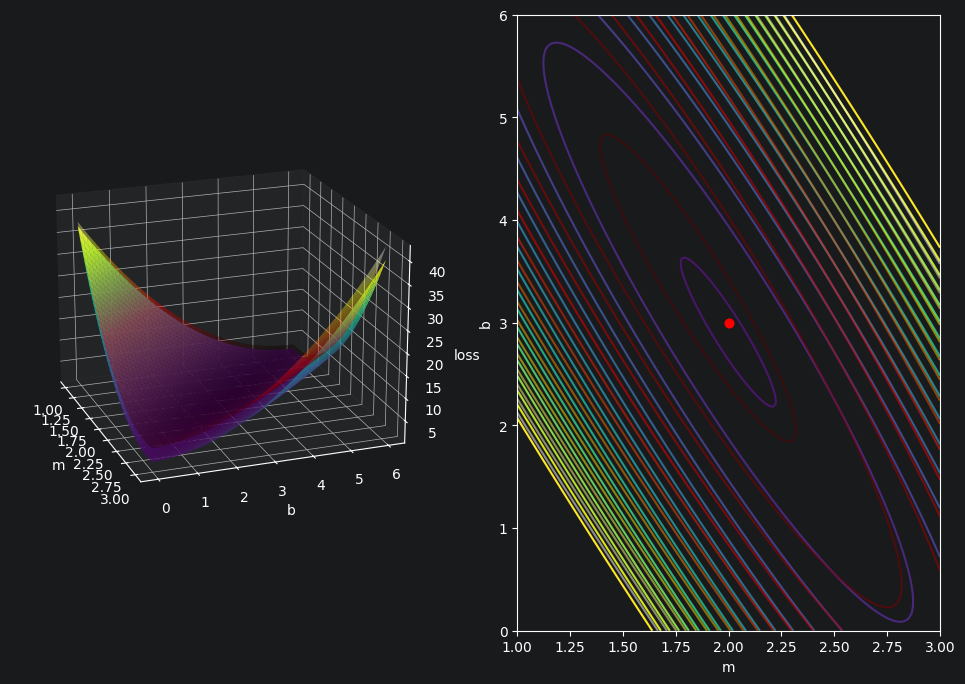

In [118]:
M = np.linspace(1,3,150)
B = np.linspace(0,6,150)
M, B = np.meshgrid(M,B)


fig = plt.figure(figsize=(12, 8))

ax1 = fig.add_subplot(121, projection='3d')
ax1.plot_surface(M, B, Loss(M,B,alpha=0), cmap='viridis', alpha=1, edgecolor='none')
ax1.view_init(elev=20, azim=-20)
ax1.set(xlabel='m', ylabel='b', zlabel='loss')

ax2 = fig.add_subplot(122)
ax2.contour(M, B, Loss(M, B, alpha=0),
           levels=[0.01,0.02,0.04,0.05,0.1,0.5,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17])
ax2.set(xlabel='m', ylabel='b')
ax2.scatter(2,3, color='red')



ax1.plot_surface(M, B, Loss(M,B, alpha=1), cmap='hot', alpha=0.4, edgecolor='none')
ax1.set(xlabel='m', ylabel='b', zlabel='loss')


ax2.contour(M, B, Loss(M, B, alpha=0.4),
           levels=[0.01,0.02,0.04,0.05,0.1,0.5,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17], cmap='hot',alpha=0.5)
ax2.set(xlabel='m', ylabel='b')
ax2.scatter(2,3, color='red')


Defining Gradient Descent Function

In [106]:
def grad_descent(x,y,alpha):
    m_curr, b_curr = (1, 1)
    iterations =1000
    learning_rate = 0.01

    fig = plt.figure(figsize=(12, 8))

    ax1 = fig.add_subplot(132, projection='3d')
    ax1.plot_surface(M, B, Loss(M,B, alpha), cmap='viridis', zorder=1, alpha=0.65, edgecolor='none')
    ax1.view_init(elev=30, azim=-6)
    ax1.set(xlabel='m', ylabel='b', zlabel='loss')

    ax2 = fig.add_subplot(133)
    ax2.contour(M, B, Loss(M, B, alpha),
                levels=[0.01,0.02,0.04,0.05,0.1,0.5,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17], zorder=1)
    ax2.set(xlabel='m', ylabel='b')
    ax2.scatter(2,3, color='red')

    ax3 = fig.add_subplot(131)
    ax3.scatter(x, y, color='red', zorder=3)


    for i in range(iterations):
        linear_model(m_curr,b_curr)(X)
        d_m = -(2/n) * sum(x*(y-linear_model(m_curr,b_curr)(x))) + alpha*np.sign(m_curr)
        d_b = -(2/n) * sum(y-linear_model(m_curr,b_curr)(x))
        m_curr = m_curr - learning_rate * d_m
        b_curr = b_curr - learning_rate * d_b
        print('m {}, b {}, iteration {}, loss {}'.format(m_curr, b_curr, i, loss(m_curr, b_curr, alpha)))
        color_idx = i / (iterations - 1)

        ax1.scatter(m_curr, b_curr, loss(m_curr, b_curr, alpha), color=plt.colormaps['plasma'](color_idx), zorder=10, alpha=1)
        ax2.scatter(m_curr,b_curr, color=plt.colormaps['plasma'](color_idx), zorder=3)
        ax3.plot(x, linear_model(m_curr,b_curr)(x), color=plt.colormaps['plasma'](color_idx))

    ax3.plot(X, linear_model(2,3)(X), color='red')



m 1.3120801598734992, b 1.0980436817738817, iteration 0, loss 17.86041299783773
m 1.5533650255868776, b 1.1754016803198757, iteration 1, loss 12.163595726178585
m 1.7398211593191137, b 1.236735426952147, iteration 2, loss 8.744767299994498
m 1.8838143924371082, b 1.285655130627839, iteration 3, loss 6.692340348337014
m 1.9949218508460185, b 1.3249568462429373, iteration 4, loss 5.459522659214661
m 2.0805608549689696, b 1.3568060800411992, iteration 5, loss 4.718334986707429
m 2.146475992206451, b 1.3828799889161187, iteration 6, loss 4.272047398314108
m 2.197116346366041, b 1.4044775113792909, iteration 7, loss 4.002656476695939
m 2.235927655512646, b 1.4226046621436241, iteration 8, loss 3.839380874017523
m 2.2655785833108975, b 1.4380405913438745, iteration 9, loss 3.7397641829045565
m 2.2881359623750974, b 1.4513887462922248, iteration 10, loss 3.678339981056388
m 2.3052005172970427, b 1.463116495397756, iteration 11, loss 3.63983285065188
m 2.3180119798488916, b 1.47358581622586, i

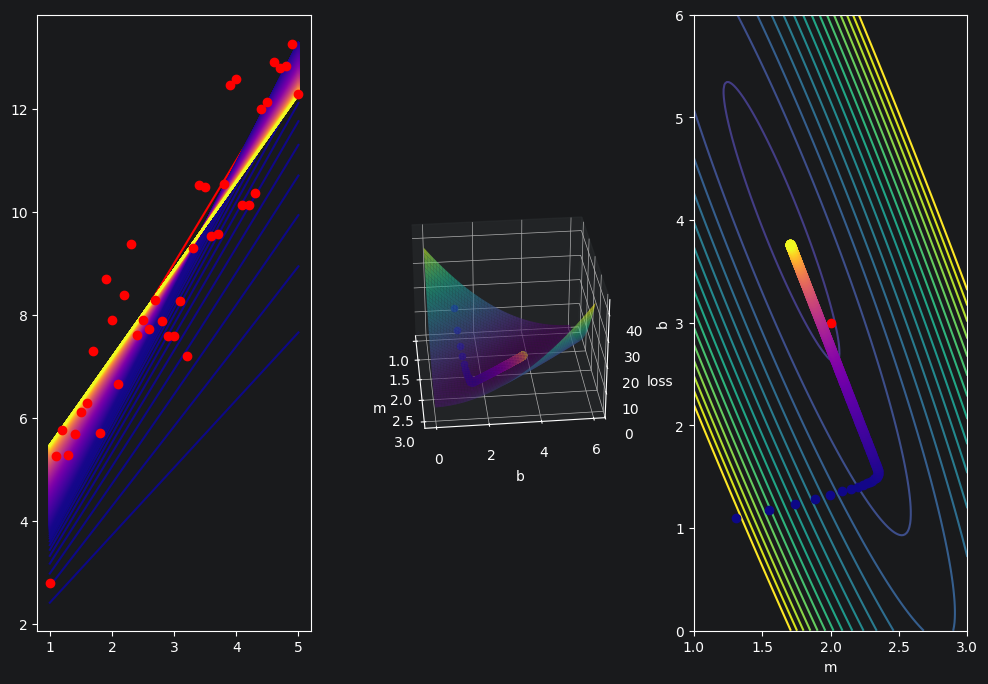

In [108]:
alpha = 1
grad_descent(X, Y, alpha)